In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Path to dataset files: /kaggle/input/breast-cancer-wisconsin-data


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv('/content/data.csv')

print(df.head())

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_worst  smoothness

In [5]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (569, 33)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-

In [6]:
df = df.drop(['id', 'Unnamed: 32'], axis=1)

print("Columns removed successfully!")

print("\nNew Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

Columns removed successfully!

New Dataset Shape: (569, 31)

Missing Values:
0


In [7]:
X = df.drop('diagnosis', axis=1)

y = df['diagnosis']

print("Independent Variables (X):")
print(X.head())

print("\nDependent Variable (Y):")
print(y.head())

Independent Variables (X):
   radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   compactness_mean  concavity_mean  concave points_mean  symmetry_mean  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   fractal_dimension_mean  ...  radius_worst  texture_worst  peri

In [8]:
y = y.map({'M': 0, 'B': 1})

print("Diagnosis converted successfully!")

print("\nTarget Values:")
print(y.head())

print("\nUnique Values:")
print(y.unique())

Diagnosis converted successfully!

Target Values:
0    0
1    0
2    0
3    0
4    0
Name: diagnosis, dtype: int64

Unique Values:
[0 1]


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)
Training Target: (455,)
Testing Target: (114,)


In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print("Feature Scaling Completed Successfully!")

Feature Scaling Completed Successfully!


In [11]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [12]:
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.head(10))

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
256    0
428    1
501    0
363    1
564    0
464    1
358    1
343    0
516    0
567    0
Name: diagnosis, dtype: int64

Predicted Values:
[0 1 0 1 0 1 1 0 0 0]


In [13]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 98.24561403508771 %


Confusion Matrix:
[[41  1]
 [ 1 71]]


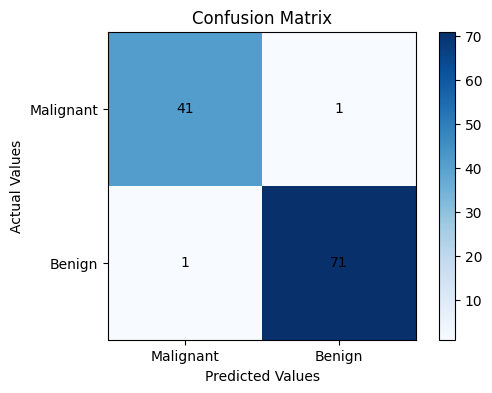

In [14]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))

plt.imshow(cm, cmap='Blues')
plt.colorbar()

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.title("Confusion Matrix")

plt.xticks([0, 1], ['Malignant', 'Benign'])
plt.yticks([0, 1], ['Malignant', 'Benign'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.show()

In [15]:
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Malignant', 'Benign']
))

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



### Conclusion

Successfully implemented a Logistic Regression model using the Breast Cancer Wisconsin dataset to classify tumors as Malignant or Benign.

The dataset was preprocessed by removing unnecessary columns, encoding categorical labels, splitting the data into training and testing sets, and applying feature scaling.

The model achieved an accuracy of **98.25%** on the test dataset.

The confusion matrix showed that 112 out of 114 predictions were correct, with only 2 incorrect predictions. The classification report showed strong precision, recall, and F1-scores for both classes.

**Result:** The Logistic Regression model successfully classified Malignant and Benign tumor samples with 98.25% accuracy.

*Note: This model is developed for educational purposes and is not intended for actual medical diagnosis.*